# 07. Multi-crop preprocessing

Anoop. Instead of stretching each image to a 128x128 square, we cut 3 square crops along its long side (start, middle, end). Nothing is distorted, padded, or thrown away.

- **Training:** every crop is its own training example, with its image's label (3 rows per image).
- **Prediction:** each image's 3 crop scores are summed and the highest class wins.

Features (RGB, HSV, LBP, HOG), scaling, and the train/val split are the same as `02_feature_extraction.ipynb`, so results compare directly with `04` and `05`. The existing feature files are not changed.

In [ ]:
# Colab setup
import os, sys

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    %pip -q install numpy pandas matplotlib scikit-learn scikit-image opencv-python-headless
    if not os.path.exists("/content/MIDS-281-project/.git"):
        !git clone --depth 1 https://github.com/sreeramchennakrish/MIDS-281-project.git /content/MIDS-281-project
    %cd /content/MIDS-281-project/notebooks

print("cwd:", os.getcwd())

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
from IPython.display import display
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

sys.path.insert(0, str(Path("../src").resolve()))
from multicrop import load_rgb, make_crops, stretch, build_features, GroupScaler, predict_vote

FEATURE_DIR = Path("../features").resolve()
DATA_DIR = Path("../data/FIRE-SMOKE-DATASET").resolve()
assert DATA_DIR.exists(), "Run 00_extract_dataset.ipynb first"


## Load the train/val split

Same images as `02`. One validation path points to a Jupyter backup copy (`.ipynb_checkpoints`), so it is dropped. The official `Test` folder is scored once at the end.

In [3]:
with np.load(FEATURE_DIR / "combined_weighted_features.npz") as data:
    saved_train, saved_val = data["train_paths"], data["val_paths"]
    y_train, y_val = data["y_train"], data["y_val"]
    classes = list(data["classes"])

def local_path(saved, split="Train"):
    p = Path(str(saved))
    return DATA_DIR / split / p.parent.name / p.name

keep = np.array(["checkpoint" not in str(p) for p in saved_val])
train_paths = [local_path(p) for p in saved_train]
val_paths = [local_path(p) for p in saved_val[keep]]
y_val = y_val[keep]

test_paths, y_test = [], []
for label, cls in enumerate(classes):
    for p in sorted((DATA_DIR / "Test" / cls).glob("*.jpg")):
        test_paths.append(p)
        y_test.append(label)
y_test = np.array(y_test)

print("Train:", len(train_paths), "Val:", len(val_paths), "Test:", len(test_paths))

Train: 2160 Val: 540 Test: 300


## What the crops look like

A wide image: the current stretched version next to the 3 crops.

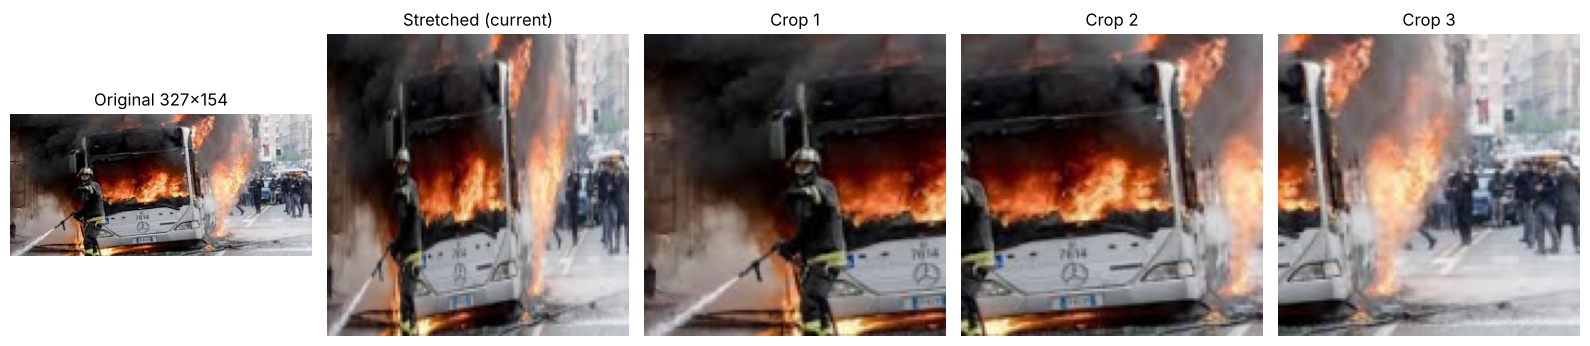

In [4]:
wide = [p for p in train_paths if "Fire" in str(p)]
img = next(im for im in map(load_rgb, wide) if im.shape[1] / im.shape[0] >= 1.6)
views = stretch(img) + make_crops(img)
titles = ["Stretched (current)", "Crop 1", "Crop 2", "Crop 3"]

fig, axes = plt.subplots(1, 5, figsize=(16, 3.5))
axes[0].imshow(img)
axes[0].set_title(f"Original {img.shape[1]}x{img.shape[0]}")
for ax, view, title in zip(axes[1:], views, titles):
    ax.imshow(view)
    ax.set_title(title)
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

## Build crop features

Each image gives 3 rows. Saved to `features/multicrop_features.npz` so reruns skip this step. That file is about 250 MB, so it is in `.gitignore` and not committed.

In [5]:
cache = FEATURE_DIR / "multicrop_features.npz"

if cache.exists():
    with np.load(cache) as data:
        feats = {s: ([data[f"{s}_{g}"] for g in range(4)], data[f"{s}_ids"]) for s in ("train", "val", "test")}
else:
    feats = {
        "train": build_features(train_paths),
        "val": build_features(val_paths),
        "test": build_features(test_paths),
    }
    np.savez(cache, **{f"{s}_{g}": groups[g] for s, (groups, _) in feats.items() for g in range(4)},
             **{f"{s}_ids": ids for s, (_, ids) in feats.items()})

(train_groups, train_ids), (val_groups, val_ids), (test_groups, test_ids) = feats["train"], feats["val"], feats["test"]

scaler = GroupScaler().fit(train_groups)
X_train, X_val, X_test = (scaler.transform(g) for g in (train_groups, val_groups, test_groups))
y_train_crops = y_train[train_ids]

print("Train rows:", X_train.shape, "Val rows:", X_val.shape, "Test rows:", X_test.shape)

Train rows: (6480, 8206) Val rows: (1620, 8206) Test rows: (900, 8206)


## Single-image baseline

The current approach (stretch each image to 128x128, one row per image), built with the same code so both are scored on val and test.

In [6]:
single = {s: build_features(paths, views=stretch)[0] for s, paths in
          (("train", train_paths), ("val", val_paths), ("test", test_paths))}
single_scaler = GroupScaler().fit(single["train"])
S_train, S_val, S_test = (single_scaler.transform(single[s]) for s in ("train", "val", "test"))

## Train and evaluate

Each model is trained on the crops, then scored per image with the summed vote. The same model is also trained on the single-image baseline.

SVM (multi-crop, validation)
              precision    recall  f1-score   support

        Fire       0.89      0.85      0.87       180
       Smoke       0.79      0.87      0.83       180
     Neutral       0.89      0.85      0.87       180

    accuracy                           0.86       540
   macro avg       0.86      0.86      0.86       540
weighted avg       0.86      0.86      0.86       540



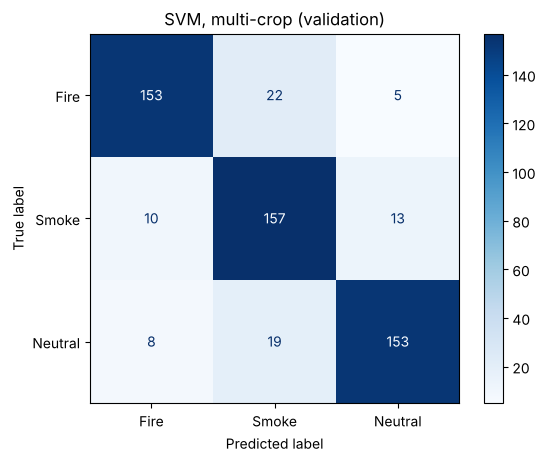

Logistic regression (multi-crop, validation)
              precision    recall  f1-score   support

        Fire       0.85      0.82      0.83       180
       Smoke       0.78      0.83      0.81       180
     Neutral       0.87      0.84      0.86       180

    accuracy                           0.83       540
   macro avg       0.83      0.83      0.83       540
weighted avg       0.83      0.83      0.83       540



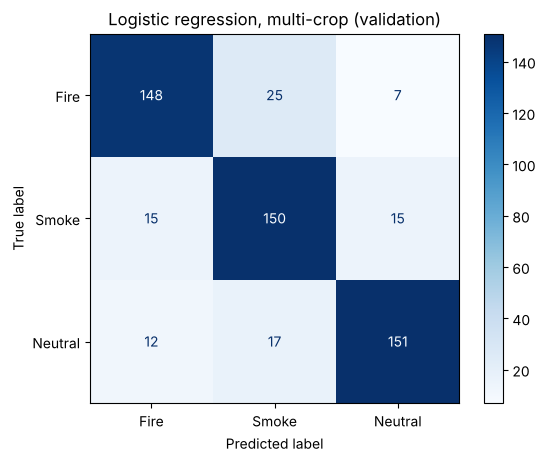

In [7]:
models = {
    "SVM": lambda: SVC(kernel="rbf", C=1.0, gamma="scale", random_state=42),
    "Logistic regression": lambda: LogisticRegression(max_iter=2000, random_state=42),
}

results = []
for name, make_model in models.items():
    baseline = make_model().fit(S_train, y_train)

    model = make_model().fit(X_train, y_train_crops)
    val_pred = predict_vote(model, X_val, val_ids)
    test_pred = predict_vote(model, X_test, test_ids)

    print("=" * 60)
    print(name, "(multi-crop, validation)")
    print(classification_report(y_val, val_pred, target_names=classes))
    ConfusionMatrixDisplay.from_predictions(y_val, val_pred, display_labels=classes, cmap="Blues")
    plt.title(f"{name}, multi-crop (validation)")
    plt.show()

    results.append({
        "Model": name,
        "Single-image val": accuracy_score(y_val, baseline.predict(S_val)),
        "Multi-crop val": accuracy_score(y_val, val_pred),
        "Single-image test": accuracy_score(y_test, baseline.predict(S_test)),
        "Multi-crop test": accuracy_score(y_test, test_pred),
    })

## Results

In [8]:
results_df = pd.DataFrame(results)
results_df["Val gain"] = results_df["Multi-crop val"] - results_df["Single-image val"]
results_df["Test gain"] = results_df["Multi-crop test"] - results_df["Single-image test"]
display(results_df.style.format({c: "{:.1%}" for c in results_df.columns if c != "Model"}))

,Model,Single-image val,Multi-crop val,Single-image test,Multi-crop test,Val gain,Test gain
0,SVM,81.5%,85.7%,76.3%,78.7%,4.3%,2.3%
1,Logistic regression,82.4%,83.1%,79.0%,81.3%,0.7%,2.3%
